# Elegir el gráfico según la pregunta

El caso conductor de la unidad es una encuesta de satisfacción de clientes de una cadena de supermercados, con datos de producto, trimestre, satisfacción, ventas y número de clientes. A partir de esta tabla se plantean preguntas analíticas que guían la elección del gráfico y la aplicación de los principios de percepción, claridad y honestidad visual.


## Pregunta analítica antes del gráfico

Antes de construir cualquier gráfico, conviene formular una pregunta analítica que oriente la exploración de los datos. El objetivo es encontrar qué combinación de variables permite extraer algún sentido de la información disponible o determinar si alguna de ellas tiene un impacto significativo. Cuando los datos no se comprenden bien, resulta difícil plantear las preguntas adecuadas sobre ellos. Por eso, la visualización no debe ser un volcado automático de gráficos, sino una búsqueda guiada por una intención analítica clara: qué se quiere averiguar y qué variables pueden aportar a esa respuesta.

**Ejemplo:** En la encuesta de satisfacción de clientes de la cadena de supermercados, antes de elegir el tipo de gráfico conviene preguntar qué combinación de variables permite entender mejor la satisfacción: por ejemplo, si la satisfacción se relaciona con el trimestre, con el producto o con el número de clientes, y cuál de esas variables tiene un impacto más significativo.

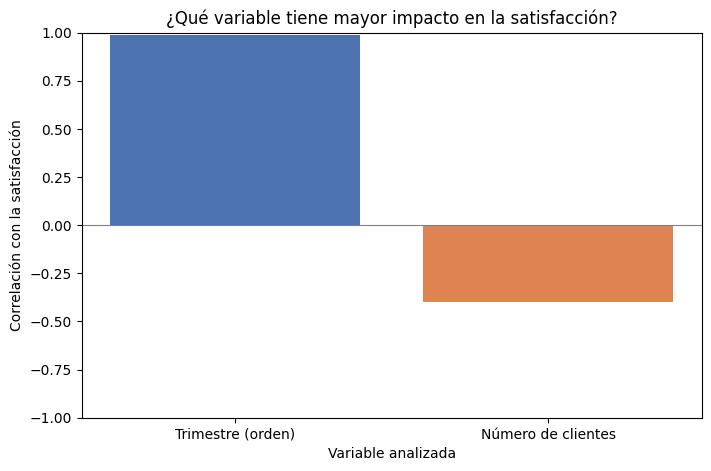

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Datos ilustrativos de la encuesta de satisfacción de clientes
datos = pd.DataFrame({
    'trimestre': ['T1', 'T2', 'T3', 'T4'],
    'satisfaccion': [72, 78, 81, 85],
    'producto': ['Lácteos', 'Bebidas', 'Limpieza', 'Panadería'],
    'clientes': [1200, 950, 800, 1100]
})

# Pregunta analítica: ¿qué variable se relaciona más con la satisfacción?
# Se comparan las correlaciones de cada variable numérica con la satisfacción
correlaciones = {
    'Trimestre (orden)': np.corrcoef(np.arange(len(datos)), datos['satisfaccion'])[0, 1],
    'Número de clientes': np.corrcoef(datos['clientes'], datos['satisfaccion'])[0, 1]
}

# Gráfico de barras para comparar el impacto de cada variable
plt.figure(figsize=(8, 5))
plt.bar(list(correlaciones.keys()), list(correlaciones.values()), color=['#4C72B0', '#DD8452'])
plt.axhline(0, color='gray', linewidth=0.8)
plt.title('¿Qué variable tiene mayor impacto en la satisfacción?')
plt.ylabel('Correlación con la satisfacción')
plt.xlabel('Variable analizada')
plt.ylim(-1, 1)
plt.show()

## Comparación entre categorías

La comparación y el ordenamiento entre categorías admiten más de una forma de representación, pero la manera tradicional de hacerlo es mediante gráficos de barras. Un gráfico de barras codifica valores cuantitativos como longitud sobre una misma línea de base, lo que permite contrastar las magnitudes de las categorías. Sin embargo, no siempre es la mejor opción para mostrar comparaciones y rankings; en ciertos casos, otras presentaciones pueden resultar más adecuadas o creativas para visualizar el orden de las categorías.

**Ejemplo:** Para ordenar los productos de la encuesta de satisfacción según su nivel de satisfacción promedio, se puede construir un gráfico de barras horizontal con los productos en el eje vertical y la satisfacción en el horizontal, todos partiendo de la misma línea de base, de modo que las longitudes permitan comparar y establecer el ranking.

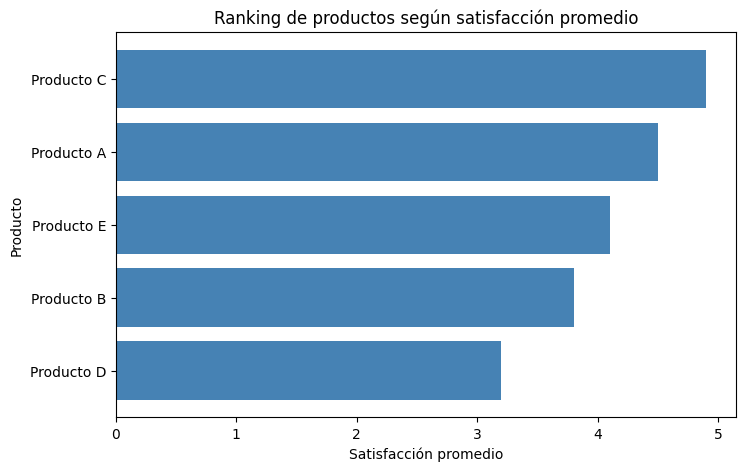

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Datos ilustrativos de la encuesta de satisfacción por producto
datos = {
    'producto': ['Producto A', 'Producto B', 'Producto C', 'Producto D', 'Producto E'],
    'satisfaccion': [4.5, 3.8, 4.9, 3.2, 4.1]
}
df = pd.DataFrame(datos)

# Ordenar los productos según su satisfacción promedio (de mayor a menor)
df = df.sort_values('satisfaccion', ascending=True)

# Crear el gráfico de barras horizontal
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(df['producto'], df['satisfaccion'], color='steelblue')

# Etiquetas y título
ax.set_xlabel('Satisfacción promedio')
ax.set_ylabel('Producto')
ax.set_title('Ranking de productos según satisfacción promedio')

# Mostrar el gráfico
plt.show()

## Tendencia temporal y series

El análisis de series o tendencias se aplica cuando los datos se miden a lo largo de fechas o períodos. Los gráficos de líneas y de áreas son los más adecuados para este tipo de análisis, ya que los valores progresan de un período a otro y permiten observar esa evolución. Al visualizar una serie temporal, es importante que los períodos del eje x estén ordenados cronológicamente y que no haya saltos en la serie. Por eso conviene diseñar un modelo dimensional con una tabla de fechas o referencia temporal que contenga todos los períodos. Si falta el dato de un mes, por ejemplo, es preferible mostrar un espacio en blanco en la línea antes que omitir ese mes de la serie. Además, al agregar un campo de agrupación en la leyenda, se puede trazar una línea por cada grupo y comparar valores a lo largo de la serie, lo que sugiere tendencias y correlaciones entre los grupos.

**Ejemplo:** Para analizar la evolución trimestral de la satisfacción promedio en la encuesta de supermercados, se traza un gráfico de líneas con los trimestres ordenados en el eje x y una línea por cada categoría de producto. Así se comparan las tendencias entre categorías y se detectan correlaciones a lo largo del año.

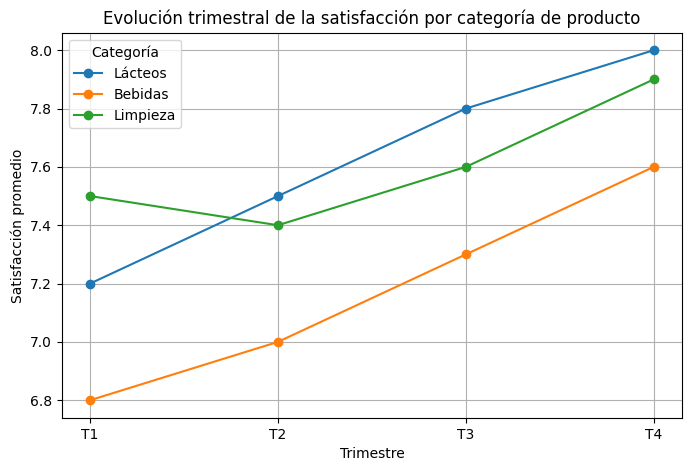

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Datos ilustrativos: satisfacción promedio por trimestre y categoría de producto
datos = {
    'Trimestre': ['T1', 'T2', 'T3', 'T4'],
    'Lácteos': [7.2, 7.5, 7.8, 8.0],
    'Bebidas': [6.8, 7.0, 7.3, 7.6],
    'Limpieza': [7.5, 7.4, 7.6, 7.9]
}
df = pd.DataFrame(datos)

# Crear el gráfico de líneas con una línea por categoría
plt.figure(figsize=(8, 5))
for categoria in ['Lácteos', 'Bebidas', 'Limpieza']:
    plt.plot(df['Trimestre'], df[categoria], marker='o', label=categoria)

# Etiquetas y título
plt.xlabel('Trimestre')
plt.ylabel('Satisfacción promedio')
plt.title('Evolución trimestral de la satisfacción por categoría de producto')
plt.legend(title='Categoría')
plt.grid(True)
plt.show()

**Errores frecuentes:**
- No ordenar los períodos del eje x cronológicamente.
- Excluir un período sin datos en lugar de mostrar un espacio en la línea.

## Distribución y dispersión de datos

Para examinar cómo se distribuyen los valores de una variable numérica se emplean gráficos que muestran su frecuencia o densidad. El histograma agrupa los valores en intervalos o bins sobre el eje x y representa en el eje y el conteo o porcentaje; el tamaño del bin es decisivo, porque uno demasiado grande puede ocultar la forma de la distribución y conviene ajustarlo para revelarla. El gráfico de densidad presenta densidades de probabilidad y la distribución de una sola variable, y el área bajo la curva enfatiza la forma de esa distribución; anotar la media ayuda a destacar el centro. El boxplot resume el rango de la variable con el mínimo, el percentil 25, el percentil 50, la mediana (no el promedio), el percentil 75 y el máximo, y resulta útil para detectar valores atípicos. En conjunto, estas herramientas permiten observar tanto la distribución como la dispersión de los datos.

**Ejemplo:** Al analizar la satisfacción registrada en la encuesta de supermercados, se agrupan los puntajes en intervalos y se representa su frecuencia para observar la forma de la distribución; luego se ajusta el tamaño de los intervalos para que esa forma se aprecie con claridad. Un gráfico de densidad con la media anotada permite destacar el centro de los puntajes, y un boxplot basado en la mediana y los percentiles revela la dispersión y posibles valores atípicos.

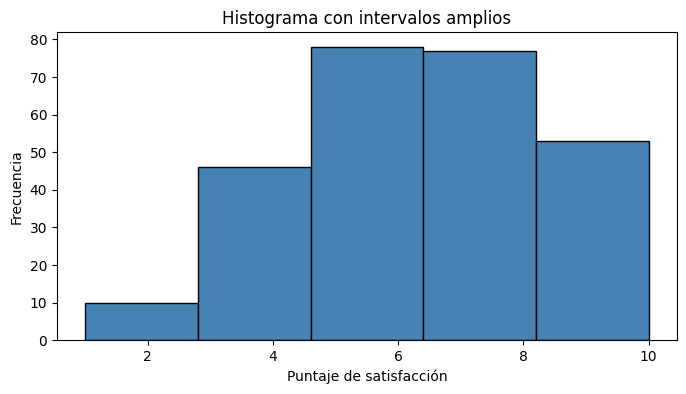

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Puntajes de satisfacción de la encuesta de supermercados (datos ilustrativos)
np.random.seed(0)
puntajes = np.concatenate([
    np.random.normal(7, 1.5, 200),
    np.random.normal(4, 1.0, 60),
    [1.0, 2.0, 9.8, 10.0]
])
puntajes = np.clip(puntajes, 0, 10)
df = pd.DataFrame({'satisfaccion': puntajes})

# 1) Histograma con intervalos amplios (pocos bins): puede ocultar la forma
plt.figure(figsize=(8, 4))
plt.hist(df['satisfaccion'], bins=5, color='steelblue', edgecolor='black')
plt.title('Histograma con intervalos amplios')
plt.xlabel('Puntaje de satisfacción')
plt.ylabel('Frecuencia')
plt.show()

# 2) Histograma con intervalos más finos: revela mejor la forma de la distribución
plt.figure(figsize=(8, 4))
plt.hist(df['satisfaccion'], bins=20, color='seagreen', edgecolor='black')
plt.title('Histograma con intervalos finos')
plt.xlabel('Puntaje de satisfacción')
plt.ylabel('Frecuencia')
plt.show()

# 3) Gráfico de densidad con la media anotada para destacar el centro
media = df['satisfaccion'].mean()
plt.figure(figsize=(8, 4))
df['satisfaccion'].plot(kind='density', color='darkorange')
plt.axvline(media, color='red', linestyle='--', label=f'Media = {media:.2f}')
plt.title('Densidad de los puntajes de satisfacción')
plt.xlabel('Puntaje de satisfacción')
plt.ylabel('Densidad')
plt.legend()
plt.show()

# 4) Boxplot: mediana, percentiles, rango y valores atípicos
plt.figure(figsize=(8, 4))
plt.boxplot(df['satisfaccion'], vert=False, patch_artist=True,
            boxprops=dict(facecolor='lightblue'))
plt.title('Boxplot de los puntajes de satisfacción')
plt.xlabel('Puntaje de satisfacción')
plt.show()

**Errores frecuentes:**
- Usar un tamaño de intervalo demasiado grande que oculta la forma de la distribución.
- No ajustar el tamaño de los intervalos para revelar la forma de la distribución.
- Confundir la mediana con el promedio en la interpretación del boxplot.

## Relación entre dos variables

Para visualizar la relación entre dos variables medidas, el gráfico de dispersión es la herramienta estándar. En este gráfico, el eje x representa una variable y el eje y la otra, de modo que cada punto corresponde a un registro. Así se puede observar si las variables tienden a moverse juntas. Cuando valores altos de una variable se asocian con valores altos de la otra, la relación es positiva; cuando los valores altos de una se asocian con valores bajos de la otra, la relación es negativa. El coeficiente de correlación mide el grado en que dos variables están asociadas.

**Ejemplo:** Al analizar la relación entre las ventas y el número de clientes de cada producto en la encuesta de satisfacción, se construye un gráfico de dispersión con matplotlib: cada punto representa un producto, con las ventas en el eje x y el número de clientes en el eje y. La nube de puntos permite ver si los productos con más clientes tienden también a tener más ventas.

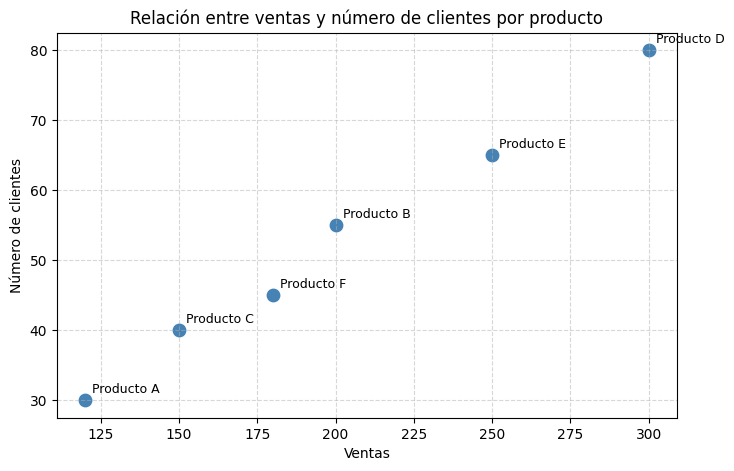

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Datos de ejemplo: ventas y número de clientes por producto
datos = {
    'producto': ['Producto A', 'Producto B', 'Producto C', 'Producto D', 'Producto E', 'Producto F'],
    'ventas': [120, 200, 150, 300, 250, 180],
    'clientes': [30, 55, 40, 80, 65, 45]
}
df = pd.DataFrame(datos)

# Gráfico de dispersión: ventas en el eje x, clientes en el eje y
plt.figure(figsize=(8, 5))
plt.scatter(df['ventas'], df['clientes'], color='steelblue', s=80)

# Etiquetar cada punto con el nombre del producto
for i, fila in df.iterrows():
    plt.annotate(fila['producto'], (fila['ventas'], fila['clientes']),
                 textcoords='offset points', xytext=(5, 5), fontsize=9)

# Títulos y etiquetas de los ejes
plt.title('Relación entre ventas y número de clientes por producto')
plt.xlabel('Ventas')
plt.ylabel('Número de clientes')
plt.grid(True, linestyle='--', alpha=0.5)

# Mostrar el gráfico
plt.show()

## Práctica

En la encuesta de satisfacción de supermercados querés responder dos preguntas: (1) ¿cómo evolucionó la satisfacción promedio a lo largo de los trimestres para cada categoría de producto? y (2) ¿qué categoría tiene la satisfacción promedio más alta? Corregí el código para que el primer gráfico sea una serie temporal con los trimestres ordenados cronológicamente y una línea por categoría, y el segundo un gráfico de barras horizontal que ordene las categorías de mayor a menor satisfacción promedio, partiendo todos de la misma línea de base. Ejecutá y compará ambos gráficos en tu cuaderno.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Datos de la encuesta de satisfacción
datos = pd.DataFrame({
    'trimestre': ['Q1', 'Q2', 'Q3', 'Q4', 'Q1', 'Q2', 'Q3', 'Q4', 'Q1', 'Q2', 'Q3', 'Q4'],
    'producto': ['Lácteos', 'Lácteos', 'Lácteos', 'Lácteos', 'Bebidas', 'Bebidas', 'Bebidas', 'Bebidas', 'Panadería', 'Panadería', 'Panadería', 'Panadería'],
    'satisfaccion': [7.2, 7.5, 7.8, 8.0, 6.5, 6.8, 7.0, 7.3, 8.1, 8.3, 8.0, 8.4]
})

# TODO: el gráfico de líneas no responde a la pregunta de tendencia temporal:
# los trimestres no están ordenados y no hay una línea por categoría.
plt.figure()
for prod in datos['producto'].unique():
    sub = datos[datos['producto'] == prod]
    plt.plot(sub['trimestre'], sub['satisfaccion'], marker='o', label=prod)
plt.xlabel('Trimestre')
plt.ylabel('Satisfacción promedio')
plt.title('Satisfacción por trimestre')
plt.legend()
plt.show()

# TODO: el gráfico de barras no ordena las categorías ni usa barras horizontales,
# por lo que no permite comparar el ranking de satisfacción promedio.
promedios = datos.groupby('producto')['satisfaccion'].mean()
plt.figure()
plt.bar(promedios.index, promedios.values)
plt.xlabel('Producto')
plt.ylabel('Satisfacción promedio')
plt.title('Satisfacción promedio por producto')
plt.show()

### Solución


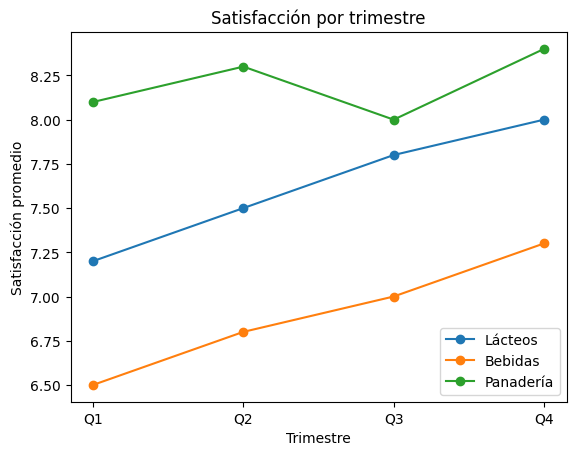

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Datos de la encuesta de satisfacción
datos = pd.DataFrame({
    'trimestre': ['Q1', 'Q2', 'Q3', 'Q4', 'Q1', 'Q2', 'Q3', 'Q4', 'Q1', 'Q2', 'Q3', 'Q4'],
    'producto': ['Lácteos', 'Lácteos', 'Lácteos', 'Lácteos', 'Bebidas', 'Bebidas', 'Bebidas', 'Bebidas', 'Panadería', 'Panadería', 'Panadería', 'Panadería'],
    'satisfaccion': [7.2, 7.5, 7.8, 8.0, 6.5, 6.8, 7.0, 7.3, 8.1, 8.3, 8.0, 8.4]
})

# Serie temporal: trimestres ordenados y una línea por categoría
orden_trimestres = ['Q1', 'Q2', 'Q3', 'Q4']
datos['trimestre'] = pd.Categorical(datos['trimestre'], categories=orden_trimestres, ordered=True)
plt.figure()
for prod in datos['producto'].unique():
    sub = datos[datos['producto'] == prod].sort_values('trimestre')
    plt.plot(sub['trimestre'], sub['satisfaccion'], marker='o', label=prod)
plt.xlabel('Trimestre')
plt.ylabel('Satisfacción promedio')
plt.title('Satisfacción por trimestre')
plt.legend()
plt.show()

# Ranking: barras horizontales ordenadas de mayor a menor
promedios = datos.groupby('producto')['satisfaccion'].mean().sort_values(ascending=True)
plt.figure()
plt.barh(promedios.index, promedios.values)
plt.xlabel('Satisfacción promedio')
plt.ylabel('Producto')
plt.title('Satisfacción promedio por producto')
plt.show()